# Training for the Basil menu classifier (EfficientNetV2-S, 41 classes).
- EfficientNetV2 in Keras normalizes internally. Feed images as float32 in the
  [0, 255] range. Do not divide by 255.
- BatchNorm is kept in inference mode via base(x, training=False), so its
  running statistics stay frozen during fine-tuning.
- Mixed precision (float16) is enabled for A100 throughput. The final Dense
  layer stays float32 for a numerically stable softmax.

In [ ]:
import os
import json
import pathlib

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix


In [ ]:
# Configuration
SEED = 42
IMG_SIZE = 384
BATCH_SIZE = 96
NUM_CLASSES = 41
PHASE1_EPOCHS = 8
PHASE2_EPOCHS = 17
PHASE1_LR = 1e-3
PHASE2_LR = 1e-4
AUTOTUNE = tf.data.AUTOTUNE

## Define  Artifacts Paths

In [ ]:
KAGGLE_DATASET = "kmader/food41"
DOWNLOAD_DIR = pathlib.Path("/content/food41")
IMAGES_ROOT = DOWNLOAD_DIR / "images"
DRIVE_DIR = pathlib.Path("/content/drive/MyDrive/MaisonRoast/BasilCNN")
LOCAL_CKPT = pathlib.Path("/content/basil_effnetv2s.keras")


## Set  sseed

In [ ]:
tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy("mixed_float16")


In [ ]:
# Check Hardware
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("policy:", tf.keras.mixed_precision.global_policy().name)


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
policy: mixed_float16


In [ ]:
#  Kaggle auth and dataset re-download (fresh VM has no images).
def configure_kaggle():

    from google.colab import userdata

    token = userdata.get("KAGGLE_API_TOKEN")
    kaggle_dir = pathlib.Path.home() / ".kaggle"
    kaggle_dir.mkdir(exist_ok=True)
    key_path = kaggle_dir / "kaggle.json"
    key_path.write_text(token)
    key_path.chmod(0o600)



Get Kaggle PAI Key Token from Colab Secrets

In [ ]:
from google.colab import userdata
userdata.get('KAGGLE_API_TOKEN')

In [ ]:
configure_kaggle()

In [ ]:
def download_dataset():

    if IMAGES_ROOT.exists() and (IMAGES_ROOT / "apple_pie").exists():

        print("Images already present, skipping download.")
        return

    DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

    os.system("pip install -q kaggle")

    code = os.system(

        f"kaggle datasets download -d {KAGGLE_DATASET} "
        f"-p {DOWNLOAD_DIR} --unzip"
    )
    if code != 0:

        raise RuntimeError("Kaggle download failed. Check token and dataset slug.")


## Re-Download Food-101 from Kaqggle to Training VM  A100 in Colab

In [ ]:
download_dataset()

Dataset we  used scoped with 40+1 food classes :
https://www.kaggle.com/datasets/kmader/food41

In [ ]:
print("images root:", IMAGES_ROOT)

images root: /content/food41/images


## Mount Google Drive in ColabOne Again in GPU  VM

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


fresh A100 VM. Re-downloads Food-101, reads the
manifests produced by the ETL from Drive, builds a tf.data pipeline, and runs
two-phase transfer learning. Best model and logs are saved to Drive.

In [ ]:
label_map = json.loads((DRIVE_DIR / "label_map.json").read_text())
INDEX_TO_CLASS = {int(k): v for k, v in label_map["index_to_class"].items()}

In [ ]:
CLASS_NAMES = [INDEX_TO_CLASS[i] for i in range(NUM_CLASSES)]
print("classes:", NUM_CLASSES)

classes: 41


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

In [ ]:
# Build the tf.data pipelines.
def load_image(path, label):

    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)  # keep [0, 255], model normalizes internally

    return img, label

In [ ]:
##  Make up my custom dataset with Manifest from ETL pipeline

In [ ]:
def make_dataset(csv_name, training):

    df = pd.read_csv(DRIVE_DIR / csv_name)

    paths = (str(IMAGES_ROOT) + "/" + df["path"]).values

    labels = df["label"].values.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:

        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return ds


In [ ]:
## Splits Datasets into three sub sets

In [ ]:
train_ds = make_dataset("train.csv", training=True)
val_ds = make_dataset("val.csv", training=False)
test_ds = make_dataset("test.csv", training=False)


In [ ]:
# Add augmentation, frozen backbone, new head.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="augmentation")


In [ ]:
# #  Build the model:
def build_model():

    base = tf.keras.applications.EfficientNetV2S(

        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3),  # 384x384 as the Original Dataset
    )

    base.trainable = False

    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = data_augmentation(inputs)

    x = base(x, training=False)  # BN stays frozen even after unfreezing weights
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.4)(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES, activation="softmax", dtype="float32"
    )(x)

    return tf.keras.Model(inputs, outputs), base


## Buildup my CNN  Model **Food Classification x41 classes**

In [ ]:
model, base_model = build_model()
metrics = [
    "accuracy",
    tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3"),
]

In [ ]:
## setup Learning Rate Logger

In [ ]:
class LearningRateLogger(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.lrs = []

    def on_epoch_end(self, epoch, logs=None):
        lr = self.model.optimizer.learning_rate
        self.lrs.append(float(np.array(lr)))


In [ ]:
lr_logger = LearningRateLogger()

##  Set Callbacks
Important on trainign loops health

In [ ]:

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(

        str(LOCAL_CKPT), monitor="val_accuracy",
        save_best_only=True, mode="max",
    ),

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss", patience=6, restore_best_weights=True,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss", factor=0.2, patience=3, min_lr=1e-6,
    ),

    tf.keras.callbacks.CSVLogger(str(DRIVE_DIR / "training_log.csv"), append=True),
    lr_logger,
]

## Compile Model

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(PHASE1_LR),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=metrics,
)

## Check CNN  Parameters with TF

In [ ]:
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 12, 12, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 41)             │        52,521 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,383,881 (77.76 MB)

 Trainable params: 52,521 (205.16 KB)

 Non-trainable params: 20,331,360 (77.56 MB)

In [ ]:
# Trainiable parameters 52.5K,  suitable for Phase I training loop,
# Eficicent Net does nto forget ImageNet weights

## Phase I  Frozen Backbone

In [ ]:
history1 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=PHASE1_EPOCHS, callbacks=callbacks,
)
# train the head with the backbone frozen.

Epoch 1/8
355/355 ━━━━━━━━━━━━━━━━━━━━ 119s 245ms/step - accuracy: 0.5042 - loss: 1.9176 - top3: 0.7120 - val_accuracy: 0.6556 - val_loss: 1.2699 - val_top3: 0.8469 - learning_rate: 0.0010
Epoch 2/8


/tmp/ipykernel_1610/714212198.py:8: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  self.lrs.append(float(np.array(lr)))


355/355 ━━━━━━━━━━━━━━━━━━━━ 71s 201ms/step - accuracy: 0.6304 - loss: 1.3390 - top3: 0.8216 - val_accuracy: 0.6936 - val_loss: 1.1058 - val_top3: 0.8678 - learning_rate: 0.0010
Epoch 3/8
355/355 ━━━━━━━━━━━━━━━━━━━━ 71s 201ms/step - accuracy: 0.6520 - loss: 1.2356 - top3: 0.8376 - val_accuracy: 0.7119 - val_loss: 1.0333 - val_top3: 0.8810 - learning_rate: 0.0010
Epoch 4/8
355/355 ━━━━━━━━━━━━━━━━━━━━ 71s 201ms/step - accuracy: 0.6654 - loss: 1.1769 - top3: 0.8489 - val_accuracy: 0.7187 - val_loss: 0.9919 - val_top3: 0.8890 - learning_rate: 0.0010
Epoch 5/8
355/355 ━━━━━━━━━━━━━━━━━━━━ 71s 201ms/step - accuracy: 0.6775 - loss: 1.1365 - top3: 0.8559 - val_accuracy: 0.7317 - val_loss: 0.9663 - val_top3: 0.8929 - learning_rate: 0.0010
Epoch 6/8
355/355 ━━━━━━━━━━━━━━━━━━━━ 70s 197ms/step - accuracy: 0.6775 - loss: 1.1221 - top3: 0.8578 - val_accuracy: 0.7309 - val_loss: 0.9530 - val_top3: 0.8914 - learning_rate: 0.0010
Epoch 7/8
355/355 ━━━━━━━━━━━━━━━━━━━━ 71s 201ms/step - accuracy: 0.68

## Phase 2: unfreeze the backbone and fine-tune with a low LR.

In [ ]:

base_model.trainable = True
model.compile(
    optimizer=tf.keras.optimizers.Adam(PHASE2_LR),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=metrics,
)

In [ ]:
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 12, 12, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 41)             │        52,521 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,383,881 (77.76 MB)

 Trainable params: 20,230,009 (77.17 MB)

 Non-trainable params: 153,872 (601.06 KB)

In [ ]:
history2 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=PHASE1_EPOCHS + PHASE2_EPOCHS,
    initial_epoch=history1.epoch[-1] + 1,
    callbacks=callbacks,
)
#  Unfreeze the backbone and fine-tune with a low LR.

Epoch 9/25
355/355 ━━━━━━━━━━━━━━━━━━━━ 390s 1s/step - accuracy: 0.7485 - loss: 0.8838 - top3: 0.8971 - val_accuracy: 0.8189 - val_loss: 0.6084 - val_top3: 0.9397 - learning_rate: 1.0000e-04
Epoch 10/25


/tmp/ipykernel_1610/714212198.py:8: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  self.lrs.append(float(np.array(lr)))


355/355 ━━━━━━━━━━━━━━━━━━━━ 333s 937ms/step - accuracy: 0.8431 - loss: 0.5416 - top3: 0.9488 - val_accuracy: 0.8427 - val_loss: 0.5492 - val_top3: 0.9455 - learning_rate: 1.0000e-04
Epoch 11/25
355/355 ━━━━━━━━━━━━━━━━━━━━ 334s 941ms/step - accuracy: 0.8860 - loss: 0.3825 - top3: 0.9684 - val_accuracy: 0.8562 - val_loss: 0.5217 - val_top3: 0.9511 - learning_rate: 1.0000e-04
Epoch 12/25
355/355 ━━━━━━━━━━━━━━━━━━━━ 332s 935ms/step - accuracy: 0.9193 - loss: 0.2735 - top3: 0.9825 - val_accuracy: 0.8583 - val_loss: 0.5322 - val_top3: 0.9508 - learning_rate: 1.0000e-04
Epoch 13/25
355/355 ━━━━━━━━━━━━━━━━━━━━ 333s 937ms/step - accuracy: 0.9397 - loss: 0.1930 - top3: 0.9902 - val_accuracy: 0.8586 - val_loss: 0.5427 - val_top3: 0.9519 - learning_rate: 1.0000e-04
Epoch 14/25
355/355 ━━━━━━━━━━━━━━━━━━━━ 332s 936ms/step - accuracy: 0.9580 - loss: 0.1413 - top3: 0.9946 - val_accuracy: 0.8607 - val_loss: 0.5630 - val_top3: 0.9543 - learning_rate: 1.0000e-04
Epoch 15/25
355/355 ━━━━━━━━━━━━━━━━━

In [ ]:
## Show Training Curves

In [ ]:
def plot_training(history1, history2, lr_logger, out_path):
    def cat(key):
        return list(history1.history.get(key, [])) + list(history2.history.get(key, []))

    acc = cat("accuracy")
    val_acc = cat("val_accuracy")
    loss = cat("loss")
    val_loss = cat("val_loss")
    # lrs = lr_logger.lrs # No longer needed for plotting
    epochs = range(1, len(loss) + 1)
    boundary = len(history1.history.get("loss", [])) + 0.5  # phase 2 start marker

    fig, axes = plt.subplots(1, 2, figsize=(12, 5)) # Changed to 1, 2 subplots

    axes[0].plot(epochs, acc, label="train")
    axes[0].plot(epochs, val_acc, label="val")
    axes[0].axvline(boundary, color="gray", linestyle="--", label="phase 2 start")
    axes[0].set_title("accuracy")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("accuracy")
    axes[0].legend()

    axes[1].plot(epochs, loss, label="train")
    axes[1].plot(epochs, val_loss, label="val")
    axes[1].axvline(boundary, color="gray", linestyle="--")
    axes[1].set_title("loss")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("loss")
    axes[1].legend()

    # Removed the third subplot code for learning rate

    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()
    print("saved figure to", out_path)

In [ ]:
## TRAINING AND VAL CURVES PLOT

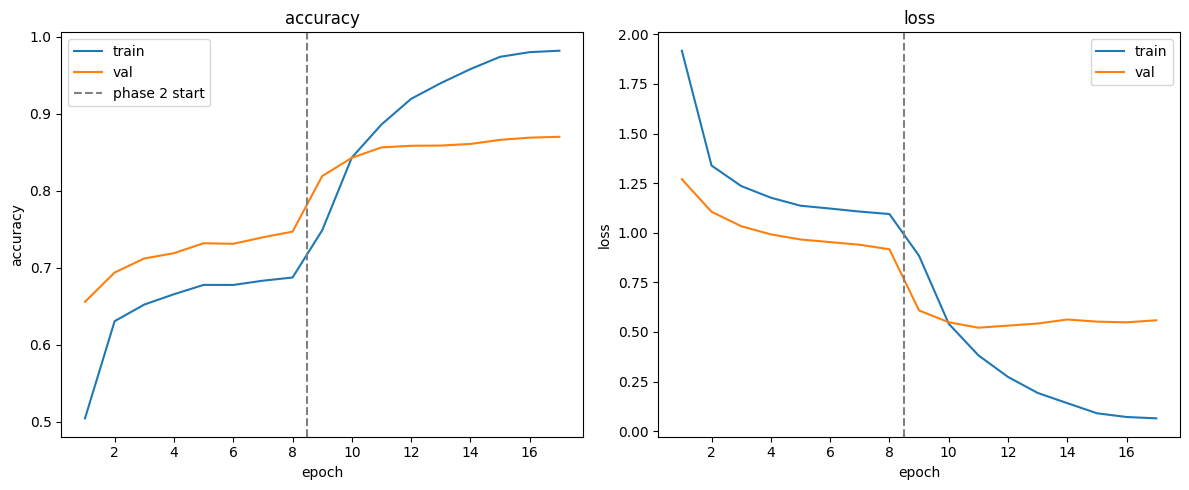

saved figure to /content/drive/MyDrive/MaisonRoast/BasilCNN/training_curves.png


In [ ]:
plot_training(
    history1, history2, lr_logger,
    str(DRIVE_DIR / "training_curves.png"),
)

In [ ]:
## Evaluate on the held-out test set  40 menu classes, no unknown.

In [ ]:
best = tf.keras.models.load_model(LOCAL_CKPT)

In [ ]:
test_metrics = best.evaluate(test_ds, return_dict=True)

42/42 ━━━━━━━━━━━━━━━━━━━━ 16s 166ms/step - accuracy: 0.9085 - loss: 0.3799 - top3: 0.9743


In [ ]:
print("test metrics:", test_metrics)


test metrics: {'accuracy': 0.9085000157356262, 'loss': 0.3798515200614929, 'top3': 0.9742500185966492}


In [ ]:
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_pred = best.predict(test_ds).argmax(axis=1)

42/42 ━━━━━━━━━━━━━━━━━━━━ 17s 287ms/step


In [ ]:
report = classification_report(
    y_true, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES, zero_division=0,
)

###  GOOd Test Results for a Difficult Food Domain  **Deserts**

In [ ]:
print(report)

                         precision    recall  f1-score   support

              apple_pie       0.83      0.81      0.82       100
                baklava       0.94      0.94      0.94       100
               beignets       0.95      0.93      0.94       100
          bread_pudding       0.71      0.79      0.75       100
      breakfast_burrito       0.96      0.91      0.93       100
             bruschetta       0.90      0.87      0.88       100
           caesar_salad       0.95      0.96      0.96       100
                cannoli       0.97      0.94      0.95       100
            carrot_cake       0.91      0.96      0.94       100
           cheese_plate       0.93      0.95      0.94       100
             cheesecake       0.81      0.79      0.80       100
         chocolate_cake       0.84      0.85      0.85       100
       chocolate_mousse       0.78      0.81      0.79       100
                churros       1.00      0.96      0.98       100
          club_sandwich 

In [ ]:
##  Save the best model, history, and report to Drive.

In [ ]:

def save_artifacts():
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    import shutil
    shutil.copy(LOCAL_CKPT, DRIVE_DIR / "basil_effnetv2s.keras")
    history = {
        "phase1": {k: [float(v) for v in vals] for k, vals in history1.history.items()},
        "phase2": {k: [float(v) for v in vals] for k, vals in history2.history.items()},
    }
    (DRIVE_DIR / "history.json").write_text(json.dumps(history, indent=2))
    (DRIVE_DIR / "test_report.txt").write_text(report)
    (DRIVE_DIR / "test_metrics.json").write_text(
        json.dumps({k: float(v) for k, v in test_metrics.items()}, indent=2)
    )
    print("saved model and reports to", DRIVE_DIR)


In [ ]:
save_artifacts()

saved model and reports to /content/drive/MyDrive/MaisonRoast/BasilCNN


Export Basil to ONNX (float32) and run it on CPU without TensorFlow.

Two stages:
1. In the training environment: rebuild a clean float32 inference model, load
   the trained weights, export a SavedModel, and convert it to ONNX with
   tf2onnx. The SavedModel route is more robust across TF/Keras versions than
   converting a Keras object directly.
2. At deploy time: load the .onnx with onnxruntime and predict. This stage
   needs only onnxruntime, numpy, and Pillow. No TensorFlow.


In [ ]:
!pip install -q tf2onnx onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 127.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 115.1 MB/s eta 0:00:00


In [ ]:
import json
import pathlib

 Rebuild a float32 inference model without augmentation and load
 the trained weights. The augmentation layers carry no weights, so the flat
 weight list still lines up with get_weights() from the trained model.

In [ ]:
IMG_SIZE = 384
NUM_CLASSES = 41
DRIVE_DIR = pathlib.Path("/content/drive/MyDrive/MaisonRoast/BasilCNN")
LOCAL_CKPT = "/content/basil_effnetv2s.keras"
SAVEDMODEL_DIR = "/content/basil_savedmodel"
ONNX_PATH = str(DRIVE_DIR / "basil_effnetv2s.onnx")

In [ ]:

def build_inference_model():
    base = tf.keras.applications.EfficientNetV2S(
        include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input")
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.4)(x)  # inactive at inference
    outputs = tf.keras.layers.Dense(
        NUM_CLASSES, activation="softmax", dtype="float32"
    )(x)
    return tf.keras.Model(inputs, outputs)


In [ ]:
tf.keras.mixed_precision.set_global_policy("float32")
trained = tf.keras.models.load_model(LOCAL_CKPT)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 906 variables whereas the saved optimizer has 910 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
infer = build_inference_model()
infer.set_weights(trained.get_weights())

In [ ]:
# Export a SavedModel, then convert to ONNX with tf2onnx.
def export_savedmodel(model, path):
    try:
        model.export(path)  # Keras 3
    except AttributeError:
        tf.saved_model.save(model, path)  # Keras 2 fallback


In [ ]:
export_savedmodel(infer, SAVEDMODEL_DIR)
# Opset 17 covers all EfficientNetV2 ops and is widely supported by onnxruntime.
os_cmd = (
    f"python -m tf2onnx.convert --saved-model {SAVEDMODEL_DIR} "
    f"--output {ONNX_PATH} --opset 17"
)

In [ ]:
## Assess ONNX Runtime

In [ ]:
import os
if os.system(os_cmd) != 0:
    raise RuntimeError("tf2onnx conversion failed.")
print("exported ONNX to", ONNX_PATH)


exported ONNX to /content/drive/MyDrive/MaisonRoast/BasilCNN/basil_effnetv2s.onnx


In [ ]:
import onnxruntime as ort

In [ ]:
sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])

In [ ]:
input_name = sess.get_inputs()[0].name
probe = np.random.uniform(0, 255, (1, IMG_SIZE, IMG_SIZE, 3)).astype(np.float32)

In [ ]:
onnx_out = sess.run(None, {input_name: probe})[0]
keras_out = infer.predict(probe, verbose=0)
print("max abs diff Keras vs ONNX:", float(np.abs(onnx_out - keras_out).max()))


max abs diff Keras vs ONNX: 1.560896635055542e-05
